In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns',None)
pd.set_option('display.float_format', lambda x: f"{x:,.2f}")
np.random.seed(42)

print("libraries loaded successfully")

libraries loaded successfully


In [2]:
n = 1200
cities = np.random.choice(['Bengaluru','Delhi','Mumbai','Pune'], size=n,
                          p=[0.35, 0.25, 0.25, 0.15])
weekday = np.random.choice(['Weekday', 'Weekend'], size=n, p=[0.72, 0.28])
order_value = np.random.gamma(shape=2.5, scale=450, size=n) + 100
delivery_minutes = np.random.normal(38, 10, size=n)
delivery_minutes += np.where(cities == 'Bengaluru', 4, 0)
delivery_minutes += np.where(weekday == 'Weekend', 3, 0)
delivery_minutes = np.clip(delivery_minutes, 12, 100).round(1)
late = (delivery_minutes > 70). astype(int)
status = np.where(np.random.rand(n) < 0.025, 'Cancelled', 'Completed')

orders = pd.DataFrame({
    "order_id": [f"ORD{i:05d}" for i in range(1, n+1)],
    "city": cities,
    "day_type": weekday,
    "order_value_inr": order_value.round(2),
    "delivery_minutes": delivery_minutes,
    "is_late": late,
    "status": status
})

orders.head()

,order_id,city,day_type,order_value_inr,delivery_minutes,is_late,status
0,ORD00001,Delhi,Weekend,748.02,51.50,0,Completed
1,ORD00002,Pune,Weekday,942.88,36.40,0,Completed
2,ORD00003,Mumbai,Weekday,"1,863.91",54.20,0,Completed
3,ORD00004,Delhi,Weekday,"2,584.40",43.60,0,Completed
4,ORD00005,Bengaluru,Weekday,"1,057.61",28.80,0,Completed


In [3]:
print("Rows:", len(orders))
print("Columns:", orders.columns.tolist())
print("Shape:",orders.shape)
print("\nData types")
print(orders.dtypes)
print("\nMissing values:")
print(orders.isna().sum())

Rows: 1200
Columns: ['order_id', 'city', 'day_type', 'order_value_inr', 'delivery_minutes', 'is_late', 'status']
Shape: (1200, 7)

Data types
order_id             object
city                 object
day_type             object
order_value_inr     float64
delivery_minutes    float64
is_late               int64
status               object
dtype: object

Missing values:
order_id            0
city                0
day_type            0
order_value_inr     0
delivery_minutes    0
is_late             0
status              0
dtype: int64


In [4]:
population = orders.copy()

sample = population.sample(n = 150, random_state=7)

population_mean_delivery = population['delivery_minutes'].mean()
sample_mean_delivery = sample['delivery_minutes'].mean()
population_late_rate = population['is_late'].mean()
sample_late_rate = sample['is_late'].mean()

print(f"Population Size: {len(population)}")
print(f"Sample Size: {len(sample)}")
print(f"Population Mean Delivery: {population_mean_delivery:.2f} minutes")
print(f"Sample Mean Delivery: {sample_mean_delivery:.2f} minutes")
print(f"Population late-order proportion: {population_late_rate:.3f}")
print(f"Sample late-order proportion: {sample_late_rate:.3f}")

Population Size: 1200
Sample Size: 150
Population Mean Delivery: 40.02 minutes
Sample Mean Delivery: 40.05 minutes
Population late-order proportion: 0.000
Sample late-order proportion: 0.000


Range of 100 sample means: 38.18 to 41.86
True finite-population mean: 40.02


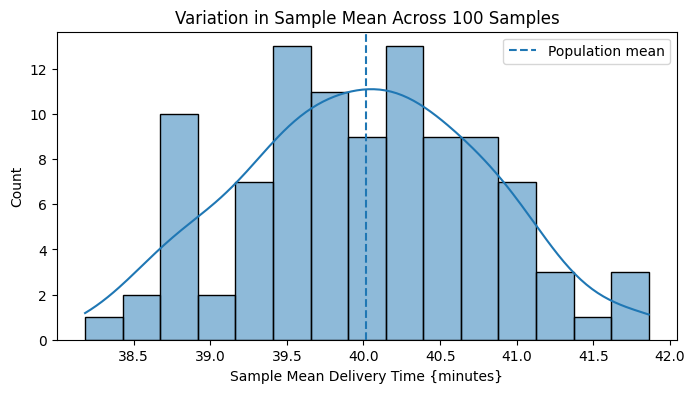

In [5]:
sample_means = []
for seed in range(100):
  s = population.sample(n = 150, random_state=seed)
  sample_means.append(s['delivery_minutes'].mean())

print("Range of 100 sample means:",
      round(min(sample_means), 2), "to", round(max(sample_means), 2))

print("True finite-population mean:", round(population_mean_delivery, 2))

plt.figure(figsize=(8,4))
sns.histplot(sample_means, bins=15, kde=True)
plt.axvline(population_mean_delivery, linestyle="--", label="Population mean")
plt.title('Variation in Sample Mean Across 100 Samples')
plt.xlabel('Sample Mean Delivery Time {minutes}')
plt.legend()
plt.show()

In [6]:
sample_sizes = [30, 100, 300, 800]
results = []

for size in sample_sizes:
  means = []
  for seed in range(100):
    s = population.sample(n=size, random_state=seed)
    means.append(s['delivery_minutes'].mean())
  results.append({
      "sample_size": size,
      "minimum_sample_mean": min(means),
      "maximum_sample_mean": max(means),
      "range": max(means) - min(means)
  })

pd.DataFrame(results)

,sample_size,minimum_sample_mean,maximum_sample_mean,range
0,30,35.93,45.60,9.67
1,100,37.88,42.61,4.73
2,300,38.58,41.09,2.50
3,800,39.53,40.48,0.95


In [7]:
census_table = population.copy()

audit_sample = population.sample(n = 100, random_state=21)

print("Census Rows:",len(census_table))
print("Audit Sample Rows:",len(audit_sample))

Census Rows: 1200
Audit Sample Rows: 100


In [8]:
numeric_summary = orders[["order_value_inr", "delivery_minutes"]].describe()
numeric_summary

,order_value_inr,delivery_minutes
count,"1,200.00","1,200.00"
mean,"1,244.98",40.02
std,720.40,10.11
min,137.19,12.00
25%,724.67,33.60
50%,"1,106.91",39.70
75%,"1,585.19",46.90
max,"6,673.27",69.40


In [9]:
print("Mean order value:", orders["order_value_inr"].mean())
print("Median order value:", orders["order_value_inr"].median())
print("Mean delivery time:", orders["delivery_minutes"].mean())
print("Median delivery time:", orders["delivery_minutes"].median())
print("90th percentile delivery time:", orders["delivery_minutes"].quantile(0.90))
print("Standard deviation of delivery time:", orders["delivery_minutes"].std())

Mean order value: 1244.9841833333332
Median order value: 1106.9099999999999
Mean delivery time: 40.016
Median delivery time: 39.7
90th percentile delivery time: 52.9
Standard deviation of delivery time: 10.105305124523277


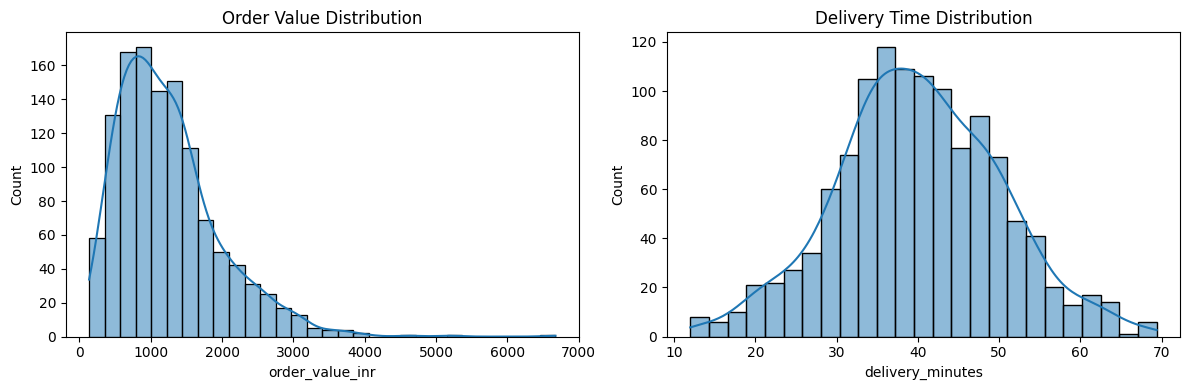

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(orders['order_value_inr'],bins=30, kde=True, ax=axes[0])
axes[0].set_title('Order Value Distribution')
sns.histplot(orders['delivery_minutes'], bins=25, kde=True, ax=axes[1])
axes[1].set_title('Delivery Time Distribution')
plt.tight_layout()
plt.show()

In [11]:
city_summary = orders.groupby('city').agg(
    orders = ('order_id', 'count'),
    mean_delivery = ('delivery_minutes', 'mean'),
    median_delivery = ('delivery_minutes', 'median'),
    late_rate = ('is_late','mean'),
    mean_order_value = ('order_value_inr', 'mean')
).sort_values('late_rate', ascending=False)

city_summary

,orders,mean_delivery,median_delivery,late_rate,mean_order_value
city,,,,,
Bengaluru,431,42.51,42.20,0.00,"1,228.04"
Delhi,283,38.44,38.70,0.00,"1,246.12"
Mumbai,290,38.92,38.60,0.00,"1,269.88"
Pune,196,38.42,38.05,0.00,"1,243.77"


In [14]:
bad_run = orders.copy()
bad_run.loc[bad_run.sample(frac=0.08, random_state=10).index, "delivery_minutes"] = np.nan
bad_run = pd.concat([bad_run, bad_run.iloc[:12]], ignore_index=True)

quality_report = pd.DataFrame({
    "metric": ["row_count", "missing_delivery_rate", "duplicate_order_id_count"],
    "value": [
        len(bad_run),
        bad_run["delivery_minutes"].isna().mean(),
        bad_run["order_id"].duplicated().sum()
    ]
})
quality_report


,metric,value
0,row_count,"1,212.00"
1,missing_delivery_rate,0.08
2,duplicate_order_id_count,12.00


In [15]:
# Build a compact decision table from observed data.
decision_view = orders.groupby("city").agg(
    order_count=("order_id", "count"),
    late_rate=("is_late", "mean"),
    median_delivery=("delivery_minutes", "median"),
    median_order_value=("order_value_inr", "median")
).reset_index()

decision_view["meets_5_percent_late_target"] = decision_view["late_rate"] <= 0.05
decision_view

,city,order_count,late_rate,median_delivery,median_order_value,meets_5_percent_late_target
0,Bengaluru,431,0.00,42.20,"1,110.03",True
1,Delhi,283,0.00,38.70,"1,089.96",True
2,Mumbai,290,0.00,38.60,"1,087.36",True
3,Pune,196,0.00,38.05,"1,162.76",True
